# BÀI THỰC HÀNH 3: MẠNG NEURAL HỒI QUY CHO BÀI TOÁN PHÂN LOẠI VĂN BẢN VÀ GÁN NHÃN CHUỖI

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses.

Bộ dữ liệu sử dụng: [UIT-VSFC](https://drive.google.com/drive/folders/1rdcXNGt_3-QUvV8EtSvVsLMVeHmk6Yqk?usp=drive_link) và [PhoNERT](https://github.com/VinAIResearch/PhoNER_COVID19).

In [1]:
from pathlib import Path
import sys
import torch

root = Path.cwd()
if not (root / "main.py").is_file():
    root = root / "Thực hành 3"
sys.path.insert(0, str(root))

from data_utils.prepare_data import prepare_vsfc, prepare_phoner
from training.experiments import run_assignment
from utils.visualization import plot_history

device = "cuda" if torch.cuda.is_available() else "cpu"
epochs = 30
batch_size = 32
learning_rate = 0.001
patience = 5
print("Device:", device)

Device: cuda


### Bài 1: Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [2]:
data_dir1 = root / "datasets" / "UIT-VSFC"
prepare_vsfc(data_dir1)

In [3]:
trainer1, result1 = run_assignment(1, data_dir=data_dir1, output_dir=root / "outputs" / "bai1", epochs=epochs, batch_size=batch_size, learning_rate=learning_rate, patience=patience, device=device)

LstmModel | device: cuda | train/dev/test: [11426, 1583, 3166]
Epoch 1/30 | train loss: 0.5287 | dev loss: 0.4118 | dev F1: 0.6945
Epoch 2/30 | train loss: 0.3988 | dev loss: 0.3902 | dev F1: 0.7149
Epoch 3/30 | train loss: 0.3504 | dev loss: 0.3956 | dev F1: 0.7222
Epoch 4/30 | train loss: 0.3204 | dev loss: 0.3774 | dev F1: 0.7418
Epoch 5/30 | train loss: 0.2920 | dev loss: 0.3809 | dev F1: 0.7359
Epoch 6/30 | train loss: 0.2604 | dev loss: 0.3846 | dev F1: 0.7586
Epoch 7/30 | train loss: 0.2250 | dev loss: 0.4132 | dev F1: 0.7435
Epoch 8/30 | train loss: 0.2015 | dev loss: 0.4307 | dev F1: 0.7327
Epoch 9/30 | train loss: 0.1819 | dev loss: 0.4504 | dev F1: 0.7441
Epoch 10/30 | train loss: 0.1525 | dev loss: 0.5028 | dev F1: 0.7193
Epoch 11/30 | train loss: 0.1388 | dev loss: 0.4847 | dev F1: 0.7172
Early stopping
Test F1: 0.7551
                  precision    recall  f1-score   support

        facility     0.9203    0.8759    0.8975       145
        lecturer     0.9188    0.9345  

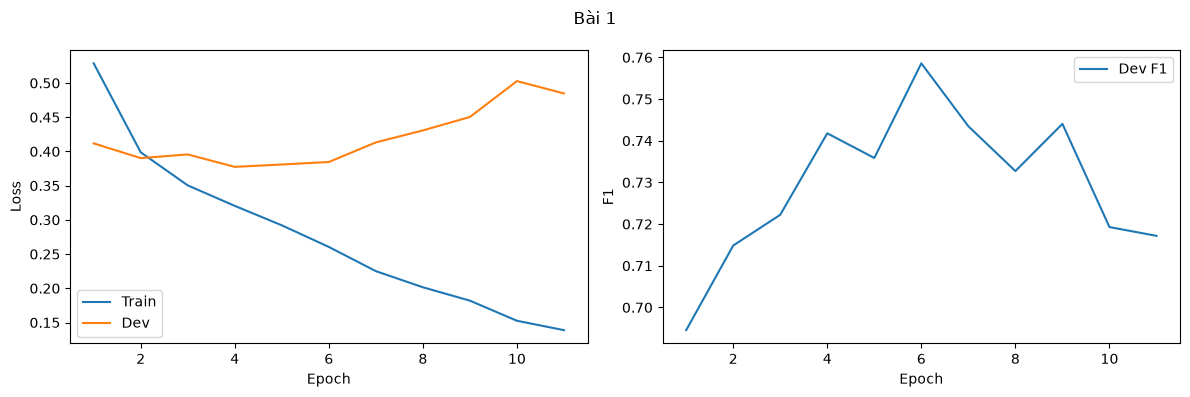

In [4]:
plot_history(result1["history"], "Bài 1")

In [5]:
print("Best epoch:", result1["best_epoch"])
print("Dev F1:", round(result1["dev_f1"], 4))
print("Test F1:", round(result1["test"]["f1"], 4))
print(result1["test"]["report"])

Best epoch: 6
Dev F1: 0.7586
Test F1: 0.7551
                  precision    recall  f1-score   support

        facility     0.9203    0.8759    0.8975       145
        lecturer     0.9188    0.9345    0.9266      2290
          others     0.5508    0.4088    0.4693       159
training_program     0.7212    0.7325    0.7268       572

        accuracy                         0.8689      3166
       macro avg     0.7778    0.7379    0.7551      3166
    weighted avg     0.8647    0.8689    0.8662      3166



### Bài 2: Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [6]:
data_dir2 = root / "datasets" / "UIT-VSFC"
prepare_vsfc(data_dir2)

In [7]:
trainer2, result2 = run_assignment(2, data_dir=data_dir2, output_dir=root / "outputs" / "bai2", epochs=epochs, batch_size=batch_size, learning_rate=learning_rate, patience=patience, device=device)

GruModel | device: cuda | train/dev/test: [11426, 1583, 3166]
Epoch 1/30 | train loss: 0.4810 | dev loss: 0.4233 | dev F1: 0.7074
Epoch 2/30 | train loss: 0.3550 | dev loss: 0.3646 | dev F1: 0.7167
Epoch 3/30 | train loss: 0.3114 | dev loss: 0.3720 | dev F1: 0.7519
Epoch 4/30 | train loss: 0.2739 | dev loss: 0.3977 | dev F1: 0.7365
Epoch 5/30 | train loss: 0.2366 | dev loss: 0.3665 | dev F1: 0.7460
Epoch 6/30 | train loss: 0.1975 | dev loss: 0.4118 | dev F1: 0.7360
Epoch 7/30 | train loss: 0.1646 | dev loss: 0.4603 | dev F1: 0.7141
Epoch 8/30 | train loss: 0.1392 | dev loss: 0.4855 | dev F1: 0.7300
Early stopping
Test F1: 0.7468
                  precision    recall  f1-score   support

        facility     0.8395    0.9379    0.8860       145
        lecturer     0.9182    0.9406    0.9292      2290
          others     0.4239    0.4906    0.4548       159
training_program     0.7911    0.6556    0.7170       572

        accuracy                         0.8664      3166
       macro 

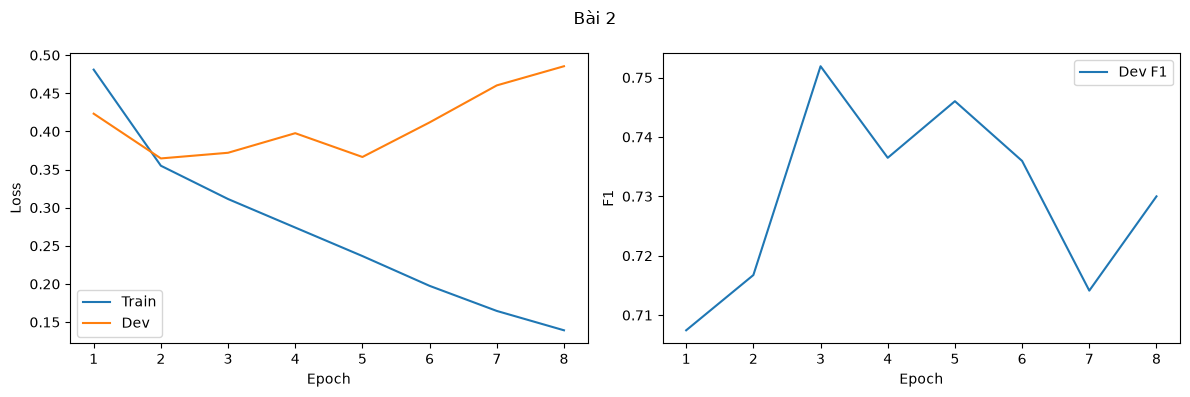

In [8]:
plot_history(result2["history"], "Bài 2")

In [9]:
print("Best epoch:", result2["best_epoch"])
print("Dev F1:", round(result2["dev_f1"], 4))
print("Test F1:", round(result2["test"]["f1"], 4))
print(result2["test"]["report"])

Best epoch: 3
Dev F1: 0.7519
Test F1: 0.7468
                  precision    recall  f1-score   support

        facility     0.8395    0.9379    0.8860       145
        lecturer     0.9182    0.9406    0.9292      2290
          others     0.4239    0.4906    0.4548       159
training_program     0.7911    0.6556    0.7170       572

        accuracy                         0.8664      3166
       macro avg     0.7432    0.7562    0.7468      3166
    weighted avg     0.8668    0.8664    0.8651      3166



### Bài 3: Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [10]:
data_dir3 = root / "datasets" / "PhoNER"
prepare_phoner(data_dir3)

In [11]:
trainer3, result3 = run_assignment(3, data_dir=data_dir3, output_dir=root / "outputs" / "bai3", epochs=epochs, batch_size=batch_size, learning_rate=learning_rate, patience=patience, device=device)

BiLstmModel | device: cuda | train/dev/test: [5027, 2000, 3000]
Epoch 1/30 | train loss: 0.7662 | dev loss: 0.3791 | dev F1: 0.6146
Epoch 2/30 | train loss: 0.1882 | dev loss: 0.2065 | dev F1: 0.8150
Epoch 3/30 | train loss: 0.0943 | dev loss: 0.1916 | dev F1: 0.8468
Epoch 4/30 | train loss: 0.0636 | dev loss: 0.2044 | dev F1: 0.8487
Epoch 5/30 | train loss: 0.0453 | dev loss: 0.1971 | dev F1: 0.8565
Epoch 6/30 | train loss: 0.0350 | dev loss: 0.1913 | dev F1: 0.8674
Epoch 7/30 | train loss: 0.0284 | dev loss: 0.2169 | dev F1: 0.8663
Epoch 8/30 | train loss: 0.0217 | dev loss: 0.1958 | dev F1: 0.8655
Epoch 9/30 | train loss: 0.0195 | dev loss: 0.2127 | dev F1: 0.8777
Epoch 10/30 | train loss: 0.0159 | dev loss: 0.2111 | dev F1: 0.8826
Epoch 11/30 | train loss: 0.0125 | dev loss: 0.2088 | dev F1: 0.8884
Epoch 12/30 | train loss: 0.0128 | dev loss: 0.2121 | dev F1: 0.8816
Epoch 13/30 | train loss: 0.0110 | dev loss: 0.2097 | dev F1: 0.8857
Epoch 14/30 | train loss: 0.0091 | dev loss: 0.2

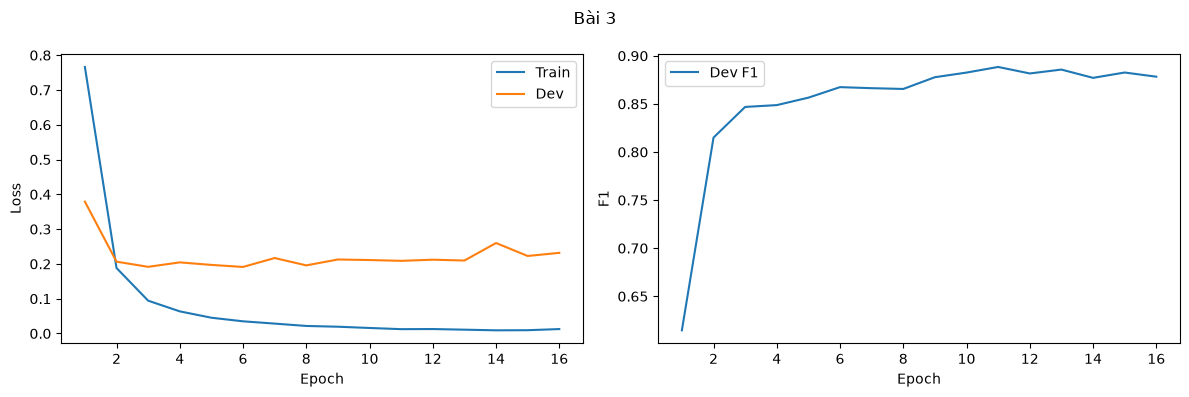

In [12]:
plot_history(result3["history"], "Bài 3")

In [13]:
print("Best epoch:", result3["best_epoch"])
print("Dev F1:", round(result3["dev_f1"], 4))
print("Test F1:", round(result3["test"]["f1"], 4))
print(result3["test"]["report"])

Best epoch: 11
Dev F1: 0.8884
Test F1: 0.8739
                     precision    recall  f1-score   support

                AGE     0.8824    0.9536    0.9166       582
               DATE     0.9585    0.9625    0.9605      1654
             GENDER     0.7744    0.9437    0.8507       462
                JOB     0.4880    0.4682    0.4779       173
           LOCATION     0.8995    0.8825    0.8909      4441
               NAME     0.6500    0.5723    0.6087       318
       ORGANIZATION     0.8486    0.7562    0.7997       771
         PATIENT_ID     0.9328    0.9137    0.9232      2005
SYMPTOM_AND_DISEASE     0.7545    0.7817    0.7678      1136
     TRANSPORTATION     0.9085    0.7720    0.8347       193

          micro avg     0.8771    0.8706    0.8739     11735
          macro avg     0.8097    0.8006    0.8031     11735
       weighted avg     0.8776    0.8706    0.8733     11735

